# Employee Attrition Prediction - Random Forest
**Project:** AI-Enhanced Employee Management Application

This notebook covers the ML module end to end: data loading, preprocessing & encoding, model training, evaluation, saving the model (joblib) and a sample prediction.

**Target:** `attrition_risk` in {Low, Moderate, High}  
**Inputs:** attendance %, salary level, overtime hours, years of experience, job satisfaction, leave frequency

In [1]:
import warnings
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
warnings.filterwarnings("ignore")
FEATURES = ["attendance_pct", "salary_level", "overtime_hours", "years_experience", "job_satisfaction", "leave_frequency"]
TARGET = "attrition_risk"

## 1. Load the dataset
`employee_attrition.csv` is produced by `generate_dataset.py` (synthetic, with documented relationships). Any real dataset with the same columns can replace it.

In [2]:
df = pd.read_csv("employee_attrition.csv")
print(df.shape)
df.head()

(3000, 7)


,attendance_pct,salary_level,overtime_hours,years_experience,job_satisfaction,leave_frequency,attrition_risk
0,92.4,3,14.9,0.5,6.7,13,Moderate
1,81.7,5,11.5,0.3,8.8,4,Low
2,96.0,1,41.7,11.7,9.3,5,High
3,97.5,5,6.0,13.4,5.7,7,Low
4,74.4,3,18.3,0.7,7.3,6,Moderate


In [3]:
display(df.describe().T.round(2))
print("\nMissing values:\n", df.isna().sum())
print("\nClass balance:\n", df[TARGET].value_counts())

,count,mean,std,min,25%,50%,75%,max
attendance_pct,3000.0,89.40,7.36,60.8,84.40,90.0,95.1,100.0
salary_level,3000.0,2.96,1.41,1.0,2.00,3.0,4.0,5.0
overtime_hours,3000.0,15.59,10.24,0.0,7.78,14.9,22.6,51.2
years_experience,3000.0,5.03,4.92,0.0,1.50,3.5,7.0,25.0
job_satisfaction,3000.0,6.43,1.91,1.0,5.10,6.4,7.8,10.0
leave_frequency,3000.0,6.01,2.53,0.0,4.00,6.0,8.0,19.0



Missing values:
 attendance_pct      0
salary_level        0
overtime_hours      0
years_experience    0
job_satisfaction    0
leave_frequency     0
attrition_risk      0
dtype: int64

Class balance:
 attrition_risk
Low         1500
Moderate     900
High         600
Name: count, dtype: int64


## 2. Exploratory analysis

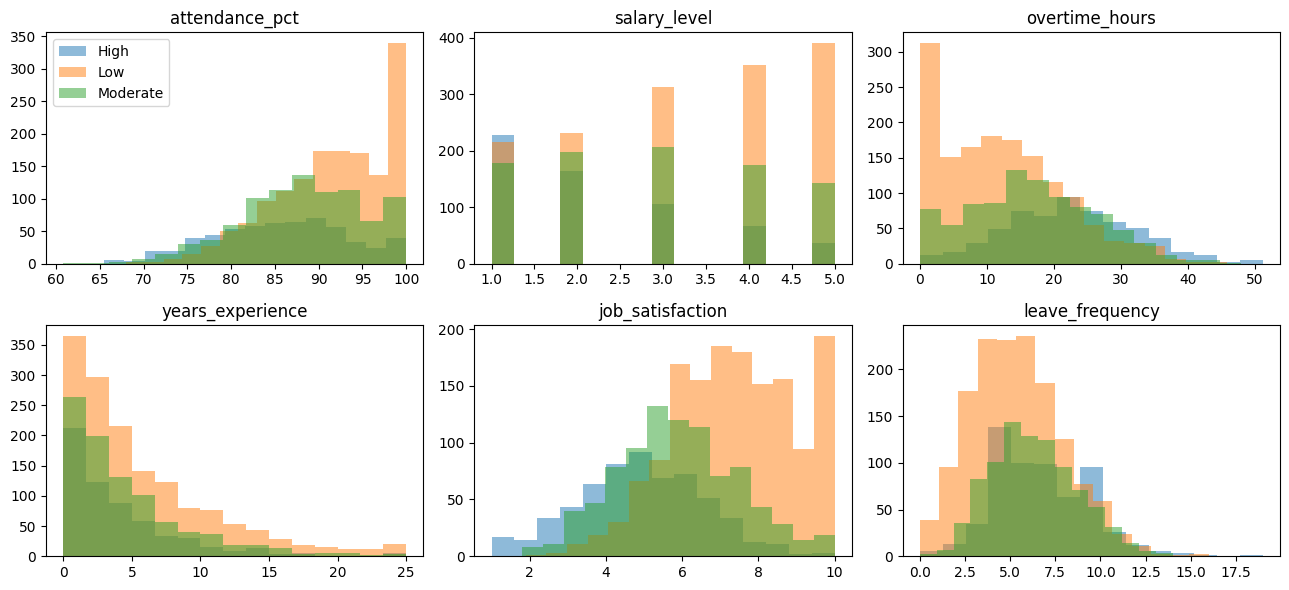

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), FEATURES):
    for label, g in df.groupby(TARGET):
        ax.hist(g[col], bins=15, alpha=.5, label=label)
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

In [5]:
print(df.groupby(TARGET)[FEATURES].mean().round(2))

                attendance_pct  salary_level  overtime_hours  \
attrition_risk                                                 
High                     85.49          2.20           22.50   
Low                      91.67          3.31           12.06   
Moderate                 88.23          2.90           16.86   

                years_experience  job_satisfaction  leave_frequency  
attrition_risk                                                       
High                        4.12              4.87             6.74  
Low                         5.67              7.37             5.54  
Moderate                    4.57              5.88             6.29  


## 3. Preprocessing & encoding
- remove duplicates and rows without a valid label
- **encode the target** ordinally (Low=0, Moderate=1, High=2)
- **median imputation** for missing feature values, inside the pipeline so it is applied identically at prediction time
- Random Forests are scale-invariant, so no feature scaling is needed

In [6]:
LABEL_ENCODING = {"Low": 0, "Moderate": 1, "High": 2}
df = df.drop_duplicates().dropna(subset=[TARGET])
df = df[df[TARGET].isin(LABEL_ENCODING)]
X = df[FEATURES]
y = df[TARGET].map(LABEL_ENCODING)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(2400, 6) (600, 6)


## 4. Train the Random Forest (with hyper-parameter search)

In [7]:
pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1)),
])
grid = {"rf__n_estimators": [200, 400], "rf__max_depth": [8, 12, None], "rf__min_samples_leaf": [1, 3, 5]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
model = search.best_estimator_
print("Best parameters:", search.best_params_)

Best parameters: {'rf__max_depth': None, 'rf__min_samples_leaf': 3, 'rf__n_estimators': 200}


## 5. Evaluate

In [8]:
pred = model.predict(X_test)
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Macro F1 : {f1_score(y_test, pred, average='macro'):.3f}")
cvs = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
print(f"5-fold CV accuracy: {cvs.mean():.3f} +/- {cvs.std():.3f}\n")
print(classification_report(y_test, pred, target_names=list(LABEL_ENCODING)))

Accuracy : 0.738
Macro F1 : 0.721


5-fold CV accuracy: 0.777 +/- 0.010

              precision    recall  f1-score   support

         Low       0.85      0.82      0.83       300
    Moderate       0.56      0.61      0.58       180
        High       0.77      0.73      0.75       120

    accuracy                           0.74       600
   macro avg       0.72      0.72      0.72       600
weighted avg       0.74      0.74      0.74       600



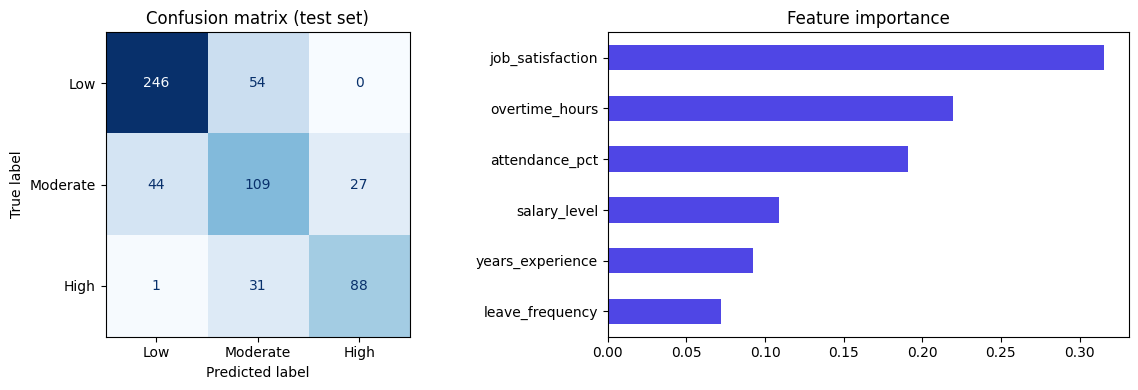

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=list(LABEL_ENCODING)).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title("Confusion matrix (test set)")
imp = pd.Series(model.named_steps["rf"].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=ax[1], color="#4f46e5"); ax[1].set_title("Feature importance")
plt.tight_layout(); plt.show()

## 6. Save the model
The whole pipeline (imputer + Random Forest) is saved with joblib. The Flask backend loads this file at start-up. `train_model.py` produces the identical artefact plus `model_meta.json` (feature order and metrics).

In [10]:
joblib.dump(model, "attrition_rf.joblib", compress=3)
loaded = joblib.load("attrition_rf.joblib")
print("Saved and reloaded OK:", type(loaded).__name__)

Saved and reloaded OK: Pipeline


## 7. Sample prediction
The backend builds the same six features from live attendance, payroll, leave and profile records.

In [11]:
decode = {v: k for k, v in LABEL_ENCODING.items()}
sample = pd.DataFrame([{"attendance_pct": 78, "salary_level": 1, "overtime_hours": 35, "years_experience": 1.5, "job_satisfaction": 3.5, "leave_frequency": 11}])
proba = loaded.predict_proba(sample)[0]
print("Predicted risk:", decode[int(loaded.predict(sample)[0])])
print({decode[int(c)]: round(float(p), 3) for c, p in zip(loaded.classes_, proba)})

Predicted risk: High
{'Low': 0.003, 'Moderate': 0.015, 'High': 0.982}
